# Registration Notebook

**Summary:** This notebook will allow you to register different camera modalities via the registration algorithm described in https://www.sciencedirect.com/science/article/pii/S0168169925006441?via%3Dihub. The algorithm will take the images from /image_dataset and register them to a provided target view. Occlusion and uncertainty errors are also detected and can be used for filtering. The algorithm requires depth images as well as a calibrated and fixed camera set up. Therefore, the 01calibration.ipynb notebook has to be executed first to generate the calibration parameters. The algorithm also allows for the computation of aligned 3D point clouds yielded from the registration process. In this notebook, parameters that you typically have to adjust are marked with **"user variables"**.

**Notes:**
1. Similar to the 01calibrate.ipynb, the images in the /image_dataset need to have consistent naming across modalities. However, the file types are currently allowed to be one of the three: ".png",".jpg", or ".npy" (extending the code to additional file types should be fairly simple though).

In [1]:
import os
import glob
import numpy as np
import imageio
from matplotlib import pyplot as plt
import matplotlib.cm as cm
import cv2
import open3d as o3d
import math
import pickle

from utils import Multimodal3DRegData #dataloader
from utils import project_depth_to_pcl,extract_pcl_ROI,pcl_to_mesh,compute_uncertainty_mesh # depth related
from utils import target_3D_registration,target_source_registration #registration related
from utils import convert_3D_thermal_colors_to_cmap,save_point_cloud #3D related

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Here, we set up two dataloader objects via Multimodal3DRegData for loading both image and depth images. In the next cell you can visualize the raw, unregistered images for different selected idx.

**Notes:**
1. The naming of modalities must be consistent with the ones for the calibration. However, with pre_modalities you have the option to switch between different versions in the dataset folder. For our dataset, we provide the hyperspectral images in three different versions: "hs_rgb": RGB representation, hs_pca: PCA generated false color image, "hs_full": numpy array that contains all 204 spectral channels of the hyperspectral image. Therefore, you can replace the string in pre_modalities with any of those three to get different visualizations. 

In [2]:
## user variables start   
#name of the dataset folder
dataset_name     = "image_dataset"

# image modalities
pre_modalities = ["infra","rgb","thermal","hs_pca"] # these names directly refer to the folder names in /image_dataset
modalities     = ["infra","rgb","thermal","hs"] # here, we map them to names consistent with the calibration 

# depth data
depth_modalities = ["depth"]
## user variables end   

ROOT_DIR = os.getcwd()
DATA_DIR = os.path.join(ROOT_DIR,dataset_name)

img_data = Multimodal3DRegData(DATA_DIR,pre_modalities)
img_data.remap_keys_to_modalities(modalities) # remapping to the standard modality keys

depth_data = Multimodal3DRegData(DATA_DIR,depth_modalities)

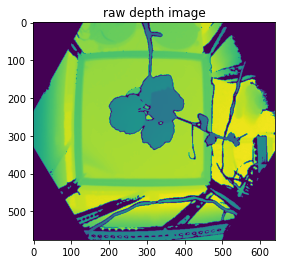

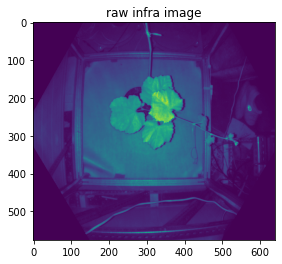

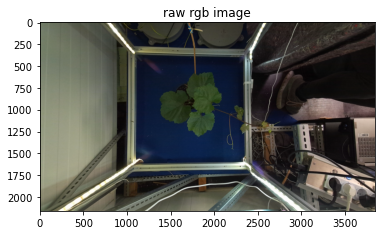

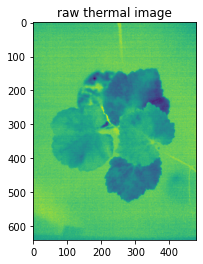

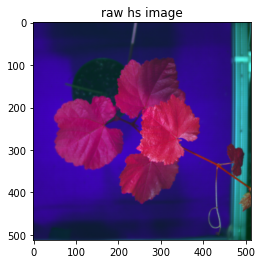

In [3]:
## user variables start   
idx = 0
## user variables end 

images = img_data[idx]

# display the original depth image
depth_img = depth_data[idx]["depth"]["img"]

plt.imshow(depth_img)
plt.title("raw depth image")
plt.show()

# display the original raw images
for m in modalities:
    
    img = images[m]["img"]
    
    if img.ndim == 3:
        if img.shape[2]>3:
            # only show the first image channel if high channel number (e.g., for hyperspec)
            plt.imshow(img[:,:,0])
        else:
            plt.imshow(img)
    else:
        plt.imshow(img)
        
    plt.title(f"raw {m} image")
    plt.show()


Next, we specify the correct set of calibration parameters, define the scale and set up a 3D bounding box.

**Notes:**
1. The scale defines the width of each checkerboard tile during the registration (In our case: 18.9753mm). Currently the calibration parameters are corresponding to this width as the base unit (width checker board tile = 1 unit). We therefore, have to realign it with the scales used in the depthmap.
2. In our case the base unit of a depthmap (Azure Kinect) is 1mm. Therefore, the scale has to be described in mm. If your depth camera has another base unit, you would have to adjust it here.
3. It can be useful to optimize the exact value of the scale manually through checking the alignment of the registration for multiple images.
4. bbox_dict defines what part of the depth information will be used for registration. For our setup, we are not interested in registering information from the background and on the sides (the pillars of our aluminum construction). z for example refers to the depth, so by setting zmax to 900/scale we exclude all background information exceeding a distance of 900mm. This selection process also saves computing time during the registration process.
5. Some practical advice for setting this bounding box: we use the free software CloudCompare for visualizing point clouds. To refine a bounding box you can first set the boundaries really wide, execute this full registration script which also saves the pointclouds in /3D_pointclouds. You can then load these point clouds in CloudCompare and then use the point picking option to get the point coordinates of background/other structures to then refine bbox_dict.  

In [4]:
# registration settings

## user variables start  
calib_name  = "2025_06_27_calibration"
scale       =  18.9753 # the width of a square of the utilized checker (mm) --> has to match depthmap metrics (for Azure Kinect they are also in mm) 

bbox_dict       ={"xmin":-400/scale,
                  "xmax":260/scale,
                  "ymin":-500/scale,
                  "ymax":180/scale,
                  "zmin":200/scale,
                  "zmax":900/scale}
## user variables end 

calib_path      = os.path.join(ROOT_DIR,"calibration_params",calib_name+".pkl")
calib_dict_orig = pickle.load(open(calib_path, 'rb'))

The following cell will do the complete registration process:
First, the meshes for ray casting are generated. Then, rays are cast from the target image into the mesh, followed by a step to cast them further into the source modalities to gather their pixel information.

**Notes:**
1. You can freely switch up which modality you want to use as the target modality (all other modalities will be registered onto this modality.). E.g. by setting target_modality to "thermal" and replacing "infra" with "thermal" in source_modalities-
2. Note, uncertainty errors are generally very rare for the plants we monitor, since in our setup all cameras are relatively close to one another.
3. All results will be saved in the results_dict. How to visualize them is described in the cells afterwards.

In [5]:

## user variables start 
idx = 0 # you can pick which image number you want to register

target_modality   = "infra" # modalitiy image into which all source modalities will be registered into
source_modalities = ["rgb","thermal","hs"] # modalities that will be registered onto the target modality

# we can upscale our target image. e.g., if the target image has shape 512 x 512, using upscale = 2 we create a 1024 x 1024 target image
# The target image on it's own then won't contain additional information, but by doing this we automatically cast more rays (1 per pixel) 
# and can therefore get denser registered information from the source modalities (e.g., from the high resolution RGB image)
upscale         = 1 # just for base modality

## user variables end



name    = img_data[idx][target_modality]["name"].split(".")[0]
print(f"currently processing: {name}")

calib_dict = calib_dict_orig.copy() #upscale adjusts calibration parameters, so we copy from the original

depth_img = depth_data[idx]["depth"]["img"]

# create point cloud, object mesh and rendering scene
pcl,depth_indices   = project_depth_to_pcl(depth_img,calib_dict["infra"])
pcl[:,0:3]          = pcl[:,0:3]/scale
pcl                 = extract_pcl_ROI(pcl,bbox_dict)
mesh,scene          = pcl_to_mesh(pcl,depth_img.shape[0],depth_img.shape[1], minAngle=2)

mesh_edges              = np.asarray(mesh.get_non_manifold_edges(allow_boundary_edges=False)) # we determine all border edges of the object mesh to create the uncertainty mesh
u_mesh,u_scene,pi_dict  = compute_uncertainty_mesh(pcl,mesh_edges,bbox_dict) #

target_img = img_data[idx][target_modality]["img"]

if upscale != 1:
     
    # upscaling also means we need to adjust the calibration intrinsic matrix
    calib_dict[target_modality]["mtx"]*= upscale 
    # value in lower right corner of Rot matrix has to stay at 1
    calib_dict[target_modality]["mtx"][2,2] = 1
    
    h = int(target_img.shape[0]*upscale)
    w = int(target_img.shape[1]*upscale)

    target_img = cv2.resize(target_img,(w,h))
 

result_dict = {}


# undistort with calibration parameters
target_img =  cv2.undistort(target_img,calib_dict[target_modality]["mtx"],calib_dict[target_modality]["dist"])

# incoming ray computations: here we calculate all necessary information from casting the rays from the target image into the scene (mesh)
reg_in  = target_3D_registration(target_modality,target_img,calib_dict,scene,u_scene)


result_dict[target_modality] = {}

result_dict[target_modality]["img"] = target_img

# insert 3D data
result_dict[target_modality]["3D_points"] = reg_in["xyz"][:, :3]*scale
result_dict[target_modality]["3D_colors"] = target_img[reg_in["obj_uv"][:,1],reg_in["obj_uv"][:,0]]

for source in source_modalities:

    # undistort source image
    source_img =  cv2.undistort(img_data[idx][source]["img"],calib_dict[source]["mtx"],calib_dict[source]["dist"])

    # outgoing ray computations
    reg_out = target_source_registration(target_modality,source,source_img,calib_dict,scene,u_scene,reg_in) 
      
    # initialize subdictionary for current source image
    result_dict[source] = {}
    
    # insert registered source image
    result_dict[source]["img"] = np.zeros((*target_img.shape[:2], source_img.shape[-1])) if source_img.ndim == 3 else np.zeros(target_img.shape[:2])
    result_dict[source]["img"][reg_out["uv_target"][:,1],reg_out["uv_target"][:,0]] = source_img[reg_out["uv_source"][:,1],reg_out["uv_source"][:,0]]
    
    # insert binary (0,1) occlusion mask
    result_dict[source]["occlusion_mask"] = np.zeros(target_img.shape[:2])
    result_dict[source]["occlusion_mask"][reg_out["occlusion_uv"][:,1],reg_out["occlusion_uv"][:,0]] = 1    

    # insert binary (0,1) incoming uncertainty masks
    result_dict[source]["in_uncertainty_mask"] = np.zeros(target_img.shape[:2])
    result_dict[source]["in_uncertainty_mask"][reg_in["uncertain_uv"][:,1],reg_in["uncertain_uv"][:,0]] = 1
    
    # insert binary (0,1) outgoing uncertainty masks
    result_dict[source]["out_uncertainty_mask"] = np.zeros(target_img.shape[:2])
    result_dict[source]["out_uncertainty_mask"][reg_out["uncertain_uv"][:,1],reg_out["uncertain_uv"][:,0]] = 1

    # insert 3D data
    result_dict[source]["3D_points"] = reg_out["xyz"][:, :3]*scale
    result_dict[source]["3D_colors"] = source_img[reg_out["uv_source"][:,1], reg_out["uv_source"][:,0]]

print("registration finished")
    

currently processing: 01grapevine


E:\01Dissertation\01data_and_code\2025_github_repository\utils.py:594: RuntimeWarning: invalid value encountered in subtract
  ray_diff = u_scene_hit - scene_hit # computes the difference between lengths between the ray hitting the object and the uncertatinty mesh
E:\01Dissertation\01data_and_code\2025_github_repository\utils.py:599: RuntimeWarning: invalid value encountered in sign
  um_bool_closer = (np.sign(ray_diff)==-1)   # marks all rays where the uncertainty mesh was hit before the object mesh, does not include np.inf consideration yet


registration finished


In the following two cells you can visualize the image registration results. 
How to display specific occlusion/uncertainty errors is shown in the second cell.

**Notes:**
1. In our setup/dataset, we have specific image modalities/cameras (infra,rgb,thermal,hs). The following visualization functions are geared toward them (e.g., using "bwr" cmap for the thermal image). If you use your own cameras/images you will have to adjust these functions to your needs.
2. For the thermal image we utilize a user defined vmin. During the calibration, the background will be assigned the value 0. If your thermal values then for example range between 18 and 24, you will have an unsufficient contrast when visualizing this plot with matplotlib. If you then set the vmin to 18°C the color contrast becomes better because of the overall smaller value range.
3. In the second cell you can replace "occlusion_mask" with "in_uncertainty_mask" or "out_uncertainty_mask" to show those respective errors.
4. Note, that such errors can only be computed as a combination of modalities. Therefore, the target modality on it's own won't contain these masks.

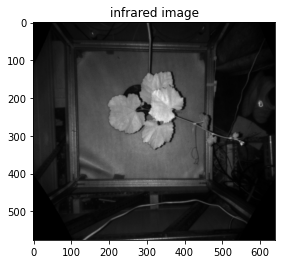

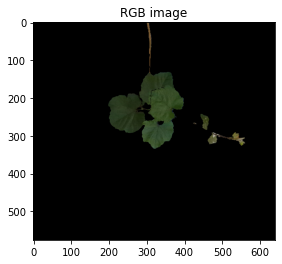

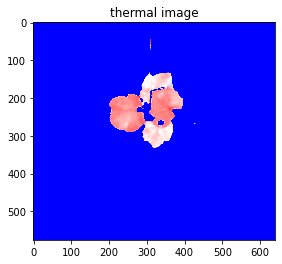

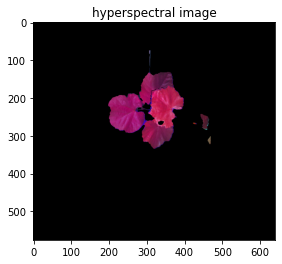

In [6]:
## user variables start 
vmin = 18 # minimum temperature color value (can be adjusted to increase contrast for thermal image)
## user variables end


plt.imshow(result_dict["infra"]["img"],cmap = "gray")
plt.title("infrared image")
plt.show()

plt.imshow(result_dict["rgb"]["img"].astype(np.uint8))
plt.title("RGB image")
plt.show()

plt.imshow(result_dict["thermal"]["img"],cmap = "bwr", vmin = vmin)
plt.title("thermal image")
plt.show()

if result_dict["hs"]["img"].shape[2] == 3:
    plt.imshow(result_dict["hs"]["img"].astype(np.uint8))
    plt.title("hyperspectral image")
    plt.show

elif result_dict["hs"]["img"].shape[2] > 3: 
    plt.imshow(result_dict["hs"]["img"][:,:,50])
    plt.title("hyperspectral image")
    plt.show()

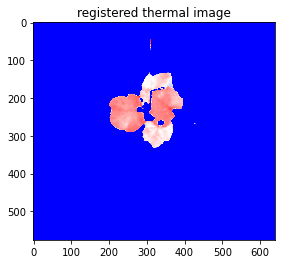

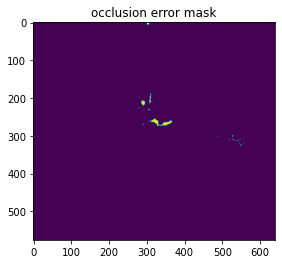

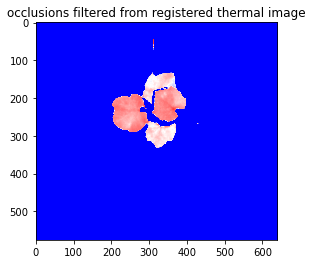

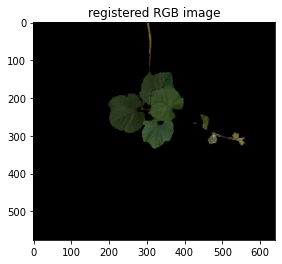

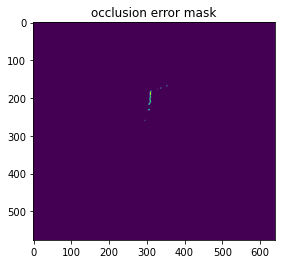

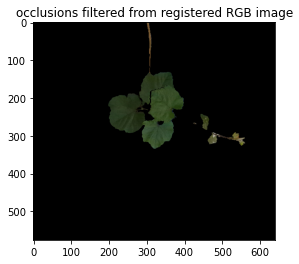

In [7]:
## user variables start 
vmin = 18 # minimum temperature color value (can be adjusted to increase contrast for thermal image)
## user variables end


if "thermal" in source_modalities:
    
    plt.imshow(result_dict["thermal"]["img"],cmap = "bwr", vmin = vmin)
    plt.title("registered thermal image")
    plt.show()

    plt.imshow(result_dict["thermal"]["occlusion_mask"])
    plt.title("occlusion error mask")
    plt.show()
    
    # now applying the masks by setting all values affected by the 
    img = result_dict["thermal"]["img"].copy()
    img[result_dict["thermal"]["occlusion_mask"] == 1] = 0
    
    plt.imshow(img,cmap = "bwr", vmin = vmin)
    plt.title("occlusions filtered from registered thermal image")
    plt.show()


if "rgb" in source_modalities:

    plt.imshow(result_dict["rgb"]["img"].astype(np.uint8))
    plt.title("registered RGB image")
    plt.show()
    
    plt.imshow(result_dict["rgb"]["occlusion_mask"].astype(np.uint8))
    plt.title("occlusion error mask")
    plt.show()
    
    img = result_dict["rgb"]["img"].copy()
    img[result_dict["rgb"]["occlusion_mask"] == 1] = 0
    
    plt.imshow(img.astype(np.uint8))
    plt.title("occlusions filtered from registered RGB image")
    plt.show()

Finally, we save the registered 3D point clouds to /3D_pointclouds. In both object and uncertainty mesh are saved as well into the folder 3D_meshes.

**Notes:**
1. the object and uncertainty meshes can be valuable for debugging. Using for example CloudCompare you can load them together with the registered pointclouds to check them for validity.
2. For thermal, again we use a specific function (convert_3D_thermal_colors_to_cmap) to have the "bwr" color map also for the saved point clouds. Depending on your use case/camera setup you will have to make adjustments.

In [8]:
OUT_3D_DIR = os.path.join(ROOT_DIR,"3D_pointclouds")
if not os.path.exists(OUT_3D_DIR):
    os.makedirs(OUT_3D_DIR)

if "thermal" in result_dict.keys():
    result_dict["thermal"]["3D_colors"] = convert_3D_thermal_colors_to_cmap(result_dict["thermal"]["3D_colors"],"bwr",vmin)
    
for key in result_dict.keys():
    
    out_path = os.path.join(OUT_3D_DIR,f"{str(idx).zfill(3)}_{name}_{key}.ply")
    save_point_cloud(result_dict[key]["3D_points"],result_dict[key]["3D_colors"],out_path)  
    
OUT_3DMESH_DIR = os.path.join(ROOT_DIR,"3D_meshes")
if not os.path.exists(OUT_3DMESH_DIR):
    os.makedirs(OUT_3DMESH_DIR)
    
mesh.scale(scale, center=(0, 0, 0))
u_mesh.scale(scale, center=(0, 0, 0))

object_mesh_path        = os.path.join(OUT_3DMESH_DIR,f"{str(idx).zfill(3)}_{name}_object_mesh.ply")
uncertainty_mesh_path   = os.path.join(OUT_3DMESH_DIR,f"{str(idx).zfill(3)}_{name}_uncertainty_mesh.ply")

o3d.io.write_triangle_mesh(object_mesh_path, mesh)
o3d.io.write_triangle_mesh(uncertainty_mesh_path, u_mesh) 

Point cloud saved to E:\01Dissertation\01data_and_code\2025_github_repository\3D_pointclouds\000_01grapevine_infra.ply
Point cloud saved to E:\01Dissertation\01data_and_code\2025_github_repository\3D_pointclouds\000_01grapevine_rgb.ply
Point cloud saved to E:\01Dissertation\01data_and_code\2025_github_repository\3D_pointclouds\000_01grapevine_thermal.ply
Point cloud saved to E:\01Dissertation\01data_and_code\2025_github_repository\3D_pointclouds\000_01grapevine_hs.ply


True